In [1]:
!pip -q install uv
with open("requirements.txt", "w") as f:
    f.write("neo4j>=5.14\nkagglehub\n")   # pandas, numpy, scipy, scikit-learn, networkx, matplotlib, tqdm sudah ada di Colab
!uv pip install --system -q -r requirements.txt
import neo4j; print("neo4j driver", neo4j.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 22.0 MB/s eta 0:00:00
neo4j driver 6.4.1


In [2]:
import kagglehub, shutil, os
path = kagglehub.dataset_download("retailrocket/ecommerce-dataset")
os.makedirs("data", exist_ok=True)
shutil.copy(os.path.join(path, "events.csv"), "data/events.csv")
print(os.listdir("data"))

Using Colab cache for faster access to the 'ecommerce-dataset' dataset.
['events.csv']


In [3]:
%%bash
set -e
apt-get -qq update
DEBIAN_FRONTEND=noninteractive apt-get -qq install -y gnupg wget openjdk-17-jre-headless
wget -qO- https://debian.neo4j.com/neotechnology.gpg.key | gpg --dearmor --yes -o /usr/share/keyrings/neotechnology.gpg
echo "deb [signed-by=/usr/share/keyrings/neotechnology.gpg] https://debian.neo4j.com stable 5" > /etc/apt/sources.list.d/neo4j.list
apt-get -qq update
DEBIAN_FRONTEND=noninteractive apt-get -qq install -y neo4j
neo4j --version

Selecting previously unselected package openjdk-17-jre-headless:amd64.
(Reading database ... 122807 files and directories currently installed.)
Preparing to unpack .../openjdk-17-jre-headless_17.0.20.1+1-1~24.04_amd64.deb ...
Unpacking openjdk-17-jre-headless:amd64 (17.0.20.1+1-1~24.04) ...
Setting up openjdk-17-jre-headless:amd64 (17.0.20.1+1-1~24.04) ...
Processing triggers for ca-certificates-java (20240118) ...
[0.025s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.025s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
done.
Preconfiguring packages ...
Selecting previously unselected package daemon.
(Reading database ... 123119 files and directories currently installed.)
Preparing to unpack .../00-daemon_0.8.4-1_amd64.deb ...
Unpacking daemon (0.8.4-1) ...
Selecting 

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [4]:
import subprocess, time, socket, shutil, os

subprocess.run('pkill -f "[n]eo4j"', shell=True)      # bersihkan sisa proses (tanda [] agar tidak membunuh dirinya sendiri)
for d in ["databases", "transactions"]:
    shutil.rmtree(f"/var/lib/neo4j/data/{d}", ignore_errors=True)
auth = "/var/lib/neo4j/data/dbms/auth.ini"
if os.path.exists(auth): os.remove(auth)

subprocess.run(["neo4j-admin", "dbms", "set-initial-password", "password"], check=True)

log = open("neo4j.log", "w")
neo_proc = subprocess.Popen(["neo4j", "console"], stdout=log, stderr=subprocess.STDOUT)

ready = False
for _ in range(90):                                   # tunggu maksimal ~3 menit
    time.sleep(2)
    try:
        socket.create_connection(("127.0.0.1", 7687), timeout=1).close(); ready = True; break
    except OSError:
        pass
time.sleep(5)
print("Neo4j siap" if ready else "Belum siap, cek log:\n" + open("neo4j.log").read()[-1500:])

Neo4j siap


In [5]:
import os, time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from neo4j import GraphDatabase
from sklearn.preprocessing import normalize

# ---------- Konfigurasi ----------
DATA_DIR   = "data"
EVENTS_CSV = os.path.join(DATA_DIR, "events.csv")
NEO4J_URI  = os.getenv("NEO4J_URI", "bolt://127.0.0.1:7687")
NEO4J_USER = os.getenv("NEO4J_USER", "neo4j")
NEO4J_PASS = os.getenv("NEO4J_PASS", "password")   # ganti sesuai kredensial Anda
NEO4J_DB   = os.getenv("NEO4J_DB", "neo4j")

TZ = "UTC"
P1_START = pd.Timestamp("2015-05-25", tz=TZ)
P1_END   = pd.Timestamp("2015-06-25", tz=TZ)   # eksklusif; sekaligus awal P2
P2_END   = pd.Timestamp("2015-07-24", tz=TZ)   # eksklusif; berarti 23 Juli ikut
SEED = 42
W = {"VIEWED": 1.0, "ADDED_TO_CART": 3.0, "BOUGHT": 5.0}   # bobot interaksi untuk VSM

## 2.1 Wrangling dan EDA
### 2.1.1 - 2.1.2 Filter periode pada `timestamp` dan simpan ke `.csv`


In [6]:
ev = pd.read_csv(EVENTS_CSV)
ev["dt"] = pd.to_datetime(ev["timestamp"], unit="ms", utc=True)
print("Rentang data asli:", ev["dt"].min(), "->", ev["dt"].max(), "| baris:", len(ev))

m1 = (ev["dt"] >= P1_START) & (ev["dt"] < P1_END)
m2 = (ev["dt"] >= P1_END)   & (ev["dt"] < P2_END)
ev["period"] = np.select([m1, m2], ["P1", "P2"], default="")

filt = ev[ev["period"] != ""].copy()
# transactionid: float+NaN -> string bersih (kosong jika bukan transaksi)
filt["transactionid"] = filt["transactionid"].astype("Int64").astype(str).replace("<NA>", "")
filt = filt.drop(columns="dt")

filt.to_csv(os.path.join(DATA_DIR, "events_filtered.csv"), index=False)
p1 = filt[filt.period == "P1"].reset_index(drop=True)
p2 = filt[filt.period == "P2"].reset_index(drop=True)
p1.to_csv(os.path.join(DATA_DIR, "events_p1_train.csv"), index=False)
p2.to_csv(os.path.join(DATA_DIR, "events_p2_test.csv"), index=False)

summary = filt.groupby(["period", "event"]).agg(
    baris=("event", "size"), visitor=("visitorid", "nunique"), item=("itemid", "nunique")
)
display(summary)

Rentang data asli: 2015-05-03 03:00:04.384000+00:00 -> 2015-09-18 02:59:47.788000+00:00 | baris: 2756101


baris  visitor    item
period event                               
P1     addtocart     15857     8924    8427
       transaction    5263     2820    3725
       view         613842   327111  119178
P2     addtocart     15520     8579    8254
       transaction    5171     2719    3682
       view         598321   334202  121199

### Impor P1 ke Neo4J (mekanisme batch)


In [7]:
driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASS))
for attempt in range(10):
    try:
        driver.verify_connectivity(); print("Terhubung ke Neo4j"); break
    except Exception as e:
        print("Menunggu server...", type(e).__name__); time.sleep(5)
else:
    raise RuntimeError("Gagal terhubung. Cek: !tail -n 40 neo4j.log")

def run(q, **params):
    with driver.session(database=NEO4J_DB) as s:
        return s.run(q, **params).data()

def create_constraints():
    run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

Q_IMPORT = {
 "view": '''UNWIND $rows AS row
            MERGE (v:Visitor {visitorId: row.visitorid})
            MERGE (i:Item {itemId: row.itemid})
            CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)''',
 "addtocart": '''UNWIND $rows AS row
            MERGE (v:Visitor {visitorId: row.visitorid})
            MERGE (i:Item {itemId: row.itemid})
            CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)''',
 "transaction": '''UNWIND $rows AS row
            MERGE (v:Visitor {visitorId: row.visitorid})
            MERGE (i:Item {itemId: row.itemid})
            CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)''',
}

def import_batch(tx, event, rows):
    tx.run(Q_IMPORT[event], rows=rows)

# ---- OPSIONAL: kosongkan graf (hati-hati jika database dipakai bersama) ----
# run("MATCH (n) DETACH DELETE n")

create_constraints()
batch_size = 5000
total_rows = len(p1)
total_chunks = (total_rows // batch_size) + 1
cols = ["visitorid", "itemid", "timestamp", "transactionid", "event"]

with driver.session(database=NEO4J_DB) as session:
    for start in tqdm(range(0, total_rows, batch_size), total=total_chunks, desc="Mengimpor batch"):
        chunk = p1.iloc[start:start + batch_size][cols]
        for event, g in chunk.groupby("event"):
            records = g.astype(object).to_dict(orient="records")
            session.execute_write(import_batch, event, records)
print("Proses impor P1 selesai.")

Terhubung ke Neo4j


Mengimpor batch:   0%|          | 0/127 [00:00<?, ?it/s]

Proses impor P1 selesai.


### 2.1.3 Komposisi subgraph (jenis simpul dan jumlahnya)


In [8]:
nodes = pd.DataFrame(run("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS jumlah ORDER BY jumlah DESC"))
rels  = pd.DataFrame(run("MATCH ()-[r]->() RETURN type(r) AS tipe, count(*) AS jumlah ORDER BY jumlah DESC"))
display(nodes); display(rels)
rels_before = rels.set_index("tipe")["jumlah"].to_dict()   # disimpan untuk soal 8 (kondisi sebelum similarity)

,label,jumlah
0,Visitor,327744
1,Item,119334


,tipe,jumlah
0,VIEWED,613842
1,ADDED_TO_CART,15857
2,BOUGHT,5263


### 2.1.4 - 2.1.5 Vector Space Modelling (VSM)

In [9]:
Q_EDGES = '''
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS u, i.itemId AS i, type(r) AS t, count(*) AS c
'''
edges = pd.DataFrame(run(Q_EDGES))
edges["w"] = edges["t"].map(W) * edges["c"]
agg = edges.groupby(["u", "i"], as_index=False)["w"].sum()

ucat = agg["u"].astype("category"); icat = agg["i"].astype("category")
user_ids = ucat.cat.categories.to_numpy(); item_ids = icat.cat.categories.to_numpy()
R = sp.csr_matrix((agg["w"].values.astype(float), (ucat.cat.codes.values, icat.cat.codes.values)),
                  shape=(len(user_ids), len(item_ids)))
Rn_user = normalize(R, norm="l2", axis=1).tocsr()        # baris user, L2-normalized (cosine)
Rn_item = normalize(R.T.tocsr(), norm="l2", axis=1).tocsr()  # baris item

def describe(name, M, axis_name):
    nnz = M.nnz; dens = nnz / (M.shape[0] * M.shape[1])
    deg = np.asarray((M > 0).sum(1)).ravel()
    return {"VSM": name, "shape": M.shape, "dimensi_fitur": M.shape[1], "nnz": nnz,
            "density": f"{dens:.2e}", "rata2_nnz_per_vektor": round(deg.mean(), 2),
            "median": int(np.median(deg)), "max": int(deg.max()),
            "vektor_dengan_1_nnz_%": round((deg == 1).mean() * 100, 1)}

vsm_table = pd.DataFrame([describe("User", R, "item"), describe("Item", R.T.tocsr(), "user")])
display(vsm_table.T)

,0,1
VSM,User,Item
shape,"(327744, 119334)","(119334, 327744)"
dimensi_fitur,119334,327744
nnz,491129,491129
density,1.26e-05,1.26e-05
rata2_nnz_per_vektor,1.5,4.12
median,1,2
max,749,1032
vektor_dengan_1_nnz_%,80.5,48.2


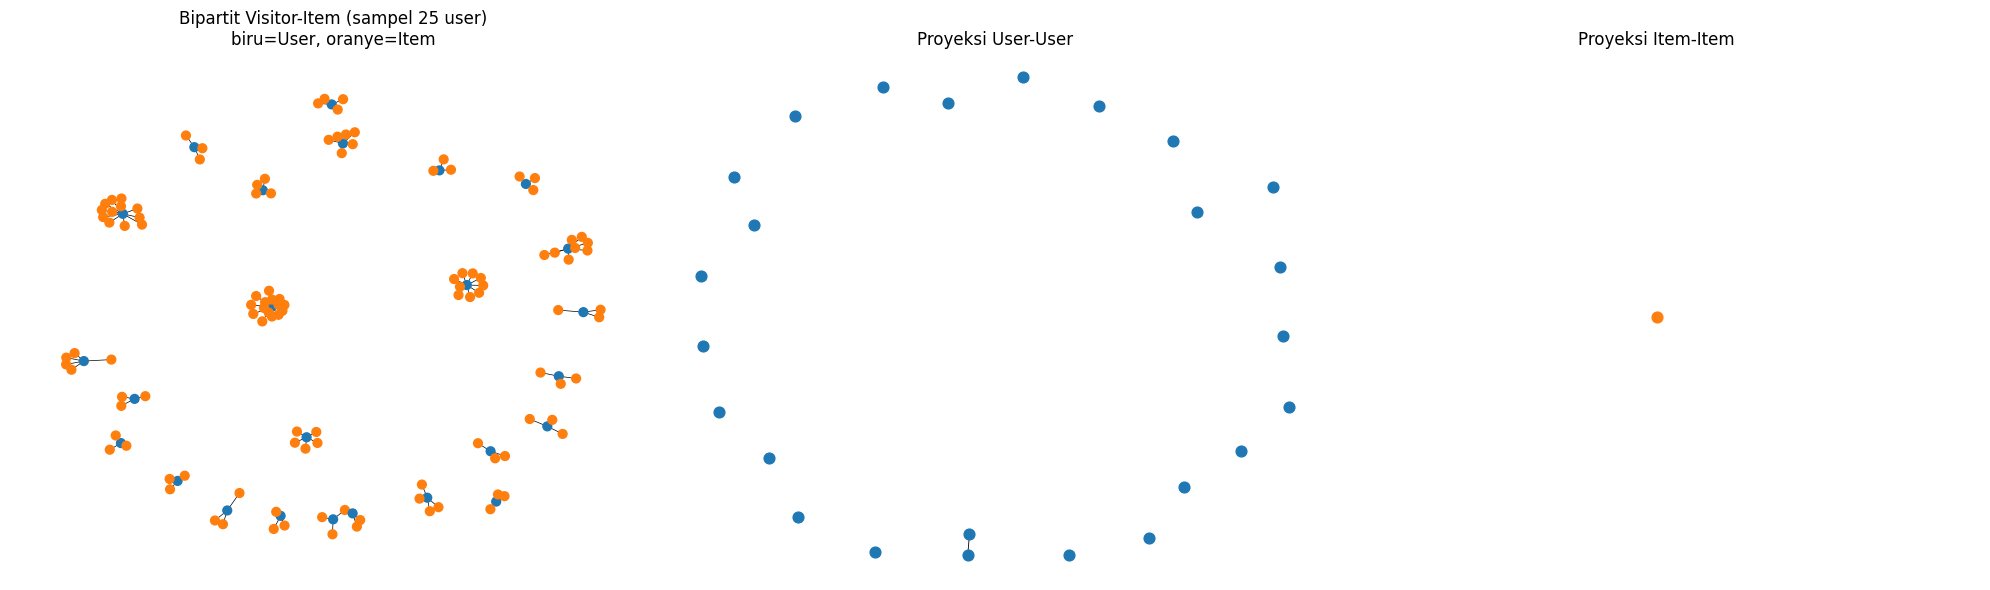

In [11]:

fig, ax = plt.subplots(1, 3, figsize=(20, 6))

pos = nx.spring_layout(G, seed=SEED)
nx.draw_networkx(
    G,
    pos=pos,
    ax=ax[0],
    node_color=colors,
    node_size=40,
    width=0.5,
    with_labels=False
)
ax[0].set_title(
    f"Bipartit Visitor-Item (sampel {len(pick)} user)\n"
    "biru=User, oranye=Item"
)

pos_uu = nx.spring_layout(G_uu, seed=SEED)
nx.draw_networkx(
    G_uu,
    pos=pos_uu,
    ax=ax[1],
    node_size=60,
    node_color="tab:blue",
    width=0.6,
    with_labels=False
)
ax[1].set_title("Proyeksi User-User")

pos_ii = nx.spring_layout(G_ii, seed=SEED)
nx.draw_networkx(
    G_ii,
    pos=pos_ii,
    ax=ax[2],
    node_size=60,
    node_color="tab:orange",
    width=0.6,
    with_labels=False
)
ax[2].set_title("Proyeksi Item-Item")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


### 2.1.6 Proyeksi mana yang lebih baik (efektif/efisien)?


In [12]:
Bin = (R > 0).astype(np.int8).tocsr()
du = np.asarray(Bin.sum(1)).ravel().astype(np.int64)   # derajat user
di = np.asarray(Bin.sum(0)).ravel().astype(np.int64)   # derajat item
pairs_user = int((di * (di - 1) // 2).sum())
pairs_item = int((du * (du - 1) // 2).sum())
nu, ni = R.shape

cmp_ = pd.DataFrame({
    "Proyeksi User-User": {"simpul": nu, "dimensi vektor": ni, "estimasi sisi (batas atas)": pairs_user,
                           "memori dense sim (GB)": round(nu * nu * 8 / 1e9, 1)},
    "Proyeksi Item-Item": {"simpul": ni, "dimensi vektor": nu, "estimasi sisi (batas atas)": pairs_item,
                           "memori dense sim (GB)": round(ni * ni * 8 / 1e9, 1)},
})
display(cmp_)
BEST = "user" if pairs_user <= pairs_item else "item"
print("Proyeksi dengan sisi lebih sedikit (lebih efisien):", BEST)

,Proyeksi User-User,Proyeksi Item-Item
simpul,327744.0,119334.0
dimensi vektor,119334.0,327744.0
estimasi sisi (batas atas),6350483.0,3812550.0
memori dense sim (GB),859.3,113.9


Proyeksi dengan sisi lebih sedikit (lebih efisien): item


**Kesimpulan 2.1.6:**

Berdasarkan tabel perbandingan, proyeksi yang dipilih adalah Item–Item karena memiliki jumlah simpul dan estimasi sisi yang lebih sedikit dibandingkan proyeksi User–User, sehingga lebih efisien dari segi komputasi. Proyeksi Item–Item memiliki 119.334 simpul dan estimasi 3.812.550 sisi, sedangkan proyeksi User–User memiliki 327.744 simpul dan estimasi 6.350.483 sisi. Selain itu, kebutuhan memori untuk menyimpan matriks similarity secara dense pada proyeksi Item–Item diperkirakan sebesar 113,9 GB, lebih rendah dibandingkan 859,3 GB pada proyeksi User–User. Dari sisi kepadatan, mayoritas user hanya memiliki satu interaksi sehingga vektor user cenderung kurang informatif untuk mengukur kemiripan. Oleh karena itu, proyeksi Item–Item lebih sesuai untuk menemukan kemiripan antarproduk dan mendukung sistem rekomendasi. Namun, karena soal 2.2 menggunakan KNN pada user, proyeksi User–User tetap relevan secara langsung dengan metode tersebut, meskipun membutuhkan sumber daya komputasi yang lebih besar.

### 2.1.7 Similarity pada graf terproyeksi (cosine, Python)


In [13]:
# ---- Pemilihan user acak (reproducible): seed tetap + daftar kandidat terurut ----
p2_rel = p2[p2["event"].isin(["addtocart", "transaction"])]
truth = p2_rel.groupby("visitorid")["itemid"].apply(set).to_dict()          # ground truth P2

deg_distinct = np.asarray((R > 0).sum(1)).ravel()
eligible = [k for k, uid in enumerate(user_ids) if deg_distinct[k] >= 3 and uid in truth]
print("Jumlah user kandidat (>=3 item di P1 dan punya addtocart/transaction di P2):", len(eligible))
rng = np.random.default_rng(SEED)
u_idx = int(rng.choice(np.array(eligible)))
TARGET_USER = user_ids[u_idx]
print("User terpilih (seed =", SEED, "):", TARGET_USER, "| derajat P1:", deg_distinct[u_idx])

if BEST == "user":
    M, ids, label, key, ref_idx = Rn_user, user_ids, "Visitor", "visitorId", u_idx
else:
    ref_idx = int(np.argmax(di)); M, ids, label, key = Rn_item, item_ids, "Item", "itemId"
REF_ID = ids[ref_idx]

sims = (M @ M[ref_idx].T).toarray().ravel()
sims[ref_idx] = -1
top5 = np.argsort(-sims)[:5]
sim_df = pd.DataFrame({"id": ids[top5], "cosine": sims[top5]})
display(sim_df)

# ---- Tulis kembali ke graf ----
rows = [{"id": int(i), "score": float(s)} for i, s in zip(sim_df["id"], sim_df["cosine"])]
Q_WRITE = f'''
UNWIND $rows AS row
MATCH (a:{label} {{{key}: $ref}}), (b:{label} {{{key}: row.id}})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.metric = 'cosine'
'''
run(Q_WRITE, rows=rows, ref=int(REF_ID))

Jumlah user kandidat (>=3 item di P1 dan punya addtocart/transaction di P2): 298
User terpilih (seed = 42 ): 138563 | derajat P1: 14


,id,cosine
0,33030,0.194018
1,256242,0.171691
2,89143,0.158887
3,33956,0.138108
4,459936,0.118450


[]

**2.1.7(a)** Cypher untuk 5 record dengan similarity tertinggi (membaca nilai yang tersimpan di graf), dan **2.1.7(b)** hasil query-nya:

In [14]:
Q_TOP5 = f'''
MATCH (a:{label} {{{key}: $ref}})-[s:SIMILAR_TO]->(b:{label})
RETURN a.{key} AS acuan, b.{key} AS tetangga, s.score AS similarity
ORDER BY similarity DESC
LIMIT 5
'''
display(pd.DataFrame(run(Q_TOP5, ref=int(REF_ID))))

,acuan,tetangga,similarity
0,5411,33030,0.194018
1,5411,256242,0.171691
2,5411,89143,0.158887
3,5411,33956,0.138108
4,5411,459936,0.118450


### 2.1.8 Graf sebelum dan sesudah perhitungan similarity


Relasi SEBELUM : {'VIEWED': 613842, 'ADDED_TO_CART': 15857, 'BOUGHT': 5263}
Relasi SESUDAH : {'ADDED_TO_CART': 15857, 'BOUGHT': 5263, 'VIEWED': 613842, 'SIMILAR_TO': 5}


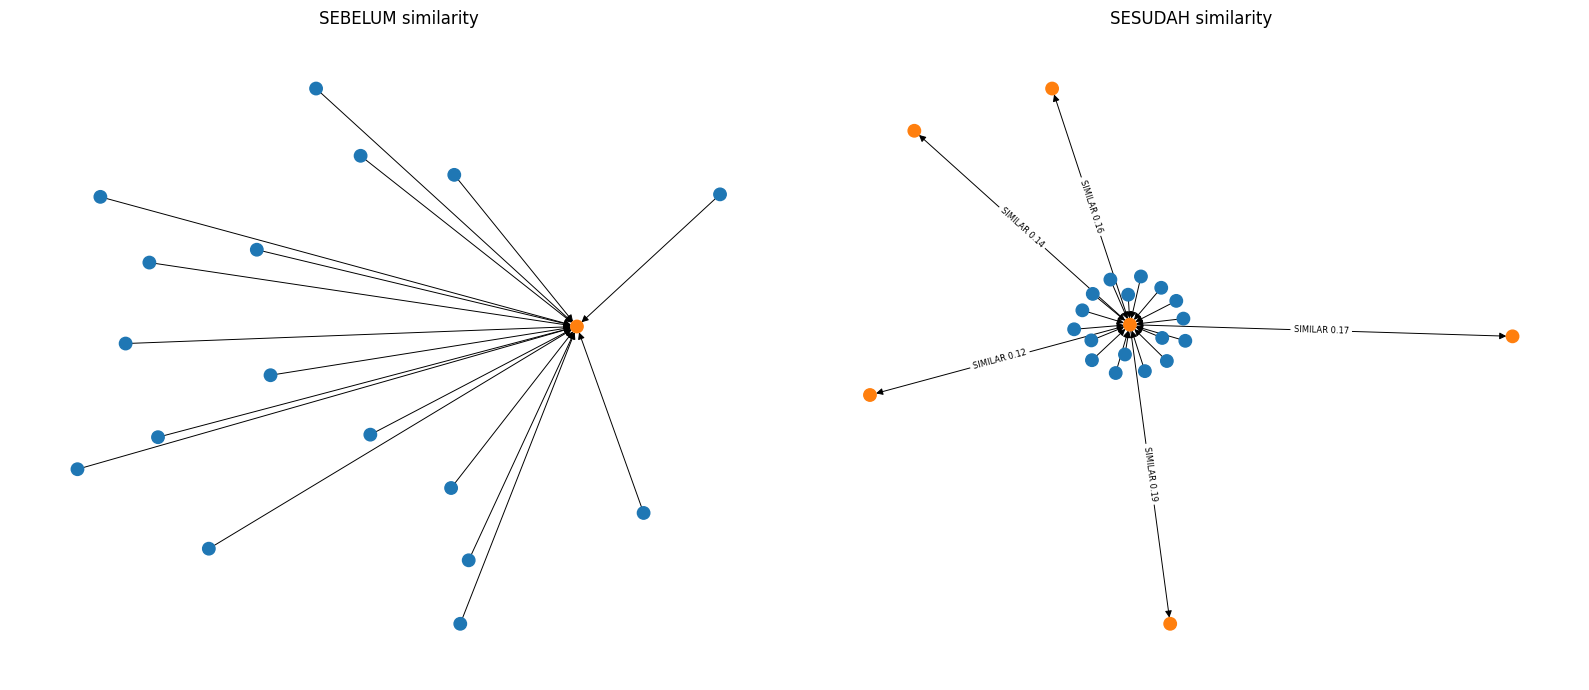

In [15]:
rels_after = {r["tipe"]: r["jumlah"] for r in run("MATCH ()-[r]->() RETURN type(r) AS tipe, count(*) AS jumlah")}
print("Relasi SEBELUM :", rels_before)
print("Relasi SESUDAH :", rels_after)

def fetch_graph(with_sim):
    G = nx.DiGraph()
    if label == "Visitor":
        qi = "MATCH (a:Visitor {visitorId:$ref})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item) RETURN 'U'+toString(a.visitorId) AS s, 'I'+toString(i.itemId) AS t, type(r) AS rel LIMIT 25"
    else:
        qi = "MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(a:Item {itemId:$ref}) RETURN 'U'+toString(v.visitorId) AS s, 'I'+toString(a.itemId) AS t, type(r) AS rel LIMIT 25"
    for r in run(qi, ref=int(REF_ID)): G.add_edge(r["s"], r["t"], rel=r["rel"])
    if with_sim:
        qs = f"MATCH (a:{label} {{{key}: $ref}})-[s:SIMILAR_TO]->(b:{label}) RETURN a.{key} AS s, b.{key} AS t, s.score AS sc"
        pre = "U" if label == "Visitor" else "I"
        for r in run(qs, ref=int(REF_ID)): G.add_edge(f"{pre}{r['s']}", f"{pre}{r['t']}", rel=f"SIMILAR {r['sc']:.2f}")
    return G

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a_, ws, ttl in zip(ax, [False, True], ["SEBELUM similarity", "SESUDAH similarity"]):
    Gx = fetch_graph(ws)
    pos = nx.spring_layout(Gx, seed=SEED)
    ncol = ["tab:blue" if n.startswith("U") else "tab:orange" for n in Gx.nodes]
    nx.draw(Gx, pos, ax=a_, node_color=ncol, node_size=80, width=0.7, arrows=True, with_labels=False)
    nx.draw_networkx_edge_labels(Gx, pos, ax=a_, font_size=6,
        edge_labels={(u, v): d["rel"] for u, v, d in Gx.edges(data=True) if d["rel"].startswith("SIMILAR")})
    a_.set_title(ttl)
plt.tight_layout(); plt.show()

## 2.2 Analytics
### 2.2.1(a) Pemilihan user acak dan rekomendasi User-KNN


In [44]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

SEED = 42
K = 5

kolom_wajib = {"visitorid", "event", "itemid"}
assert kolom_wajib.issubset(p1.columns), "Kolom P1 tidak lengkap."
assert kolom_wajib.issubset(p2.columns), "Kolom P2 tidak lengkap."

p1 = p1.dropna(subset=["visitorid", "itemid"]).copy()
p2 = p2.dropna(subset=["visitorid", "itemid"]).copy()

p1["visitorid"] = p1["visitorid"].astype(int)
p1["itemid"] = p1["itemid"].astype(int)
p2["visitorid"] = p2["visitorid"].astype(int)
p2["itemid"] = p2["itemid"].astype(int)

users_transaksi_p2 = set(
    p2.loc[p2["event"] == "transaction", "visitorid"].unique()
)
users_p1 = set(p1["visitorid"].unique())
kandidat_user = sorted(users_transaksi_p2 & users_p1)

if not kandidat_user:
    raise ValueError(
        "Tidak ditemukan user yang bertransaksi di P2 "
        "dan memiliki interaksi di P1."
    )

rng = np.random.default_rng(SEED)
user_id = int(rng.choice(kandidat_user))

print("Jumlah kandidat user:", len(kandidat_user))
print("User terpilih:", user_id)

interaksi = p1[["visitorid", "itemid"]].drop_duplicates()

user_ids = np.array(sorted(interaksi["visitorid"].unique()))
item_ids = np.array(sorted(interaksi["itemid"].unique()))

user_to_idx = {u: i for i, u in enumerate(user_ids)}
item_to_idx = {item: i for i, item in enumerate(item_ids)}

baris = interaksi["visitorid"].map(user_to_idx).to_numpy()
kolom = interaksi["itemid"].map(item_to_idx).to_numpy()
nilai = np.ones(len(interaksi), dtype=np.float32)

X = csr_matrix(
    (nilai, (baris, kolom)),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.float32
)

print("Ukuran matriks user-item:", X.shape)
print("Jumlah interaksi unik:", X.nnz)

knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=min(K + 1, len(user_ids))
)
knn.fit(X)

target_idx = user_to_idx[user_id]
distances, indices = knn.kneighbors(X[target_idx])

neighbors = []
neighbor_similarities = []

for idx, distance in zip(indices[0], distances[0]):
    neighbor_id = int(user_ids[idx])

    if neighbor_id == user_id:
        continue

    neighbors.append(neighbor_id)
    neighbor_similarities.append(max(0.0, 1.0 - float(distance)))

    if len(neighbors) == K:
        break

print("\nLima tetangga terdekat:")
print(pd.DataFrame({
    "visitorid": neighbors,
    "cosine_similarity": neighbor_similarities
}))


Jumlah kandidat user: 285
User terpilih: 148453
Ukuran matriks user-item: (327744, 119334)
Jumlah interaksi unik: 491129

Lima tetangga terdekat:
   visitorid  cosine_similarity
0    1396958                1.0
1    1314815                1.0
2    1240797                1.0
3    1282975                1.0
4    1231588                1.0


### 2.2.1(b) Tiga item yang diiklankan (k = 5)


In [45]:
target_vector = X[target_idx]
seen_indices = set(target_vector.indices)

neighbor_rows = [user_to_idx[u] for u in neighbors]
weights = np.asarray(neighbor_similarities, dtype=np.float32)

item_scores = np.zeros(len(item_ids), dtype=np.float64)

if neighbor_rows:
    neighbor_matrix = X[neighbor_rows]
    item_scores = np.asarray(
        neighbor_matrix.T.dot(weights)
    ).ravel()

item_scores[list(seen_indices)] = 0

ranked_indices = []
metode_item = {}

utama = sorted(
    np.flatnonzero(item_scores > 0),
    key=lambda i: (-item_scores[i], int(item_ids[i]))
)

for i in utama:
    ranked_indices.append(int(i))
    metode_item[int(i)] = "KNN berbobot cosine similarity"

if len(ranked_indices) < 5 and neighbor_rows:
    neighbor_counts = np.asarray(
        (X[neighbor_rows] > 0).sum(axis=0)
    ).ravel()

    neighbor_counts[list(seen_indices)] = 0

    fallback_neighbors = sorted(
        np.flatnonzero(neighbor_counts > 0),
        key=lambda i: (-neighbor_counts[i], int(item_ids[i]))
    )

    for i in fallback_neighbors:
        i = int(i)
        if i not in metode_item:
            ranked_indices.append(i)
            metode_item[i] = "Frekuensi interaksi tetangga"
        if len(ranked_indices) >= 5:
            break

if len(ranked_indices) < 5:
    popular_items = (
        p1.groupby("itemid")
        .size()
        .sort_values(ascending=False)
    )

    for item in popular_items.index:
        item = int(item)

        if item not in item_to_idx:
            continue

        i = item_to_idx[item]

        if i in seen_indices or i in metode_item:
            continue

        ranked_indices.append(i)
        metode_item[i] = "Fallback popularitas P1"

        if len(ranked_indices) >= 5:
            break

top5_items = [int(item_ids[i]) for i in ranked_indices[:5]]

top3_items = top5_items[:3]

hasil_rekomendasi = pd.DataFrame({
    "Peringkat": range(1, len(top3_items) + 1),
    "ItemID": top3_items,
    "Metode": [
        metode_item[item_to_idx[item]]
        for item in top3_items
    ]
})

print("User:", user_id)
print("\nTiga item yang direkomendasikan:")
display(hasil_rekomendasi)

print("Daftar Top-5 untuk evaluasi:", top5_items)

if len(top5_items) < 5:
    print(
        "PERHATIAN: hanya tersedia", len(top5_items),
        "item yang belum pernah dilihat. "
        "Evaluasi menggunakan daftar yang tersedia."
    )


User: 148453

Tiga item yang direkomendasikan:


,Peringkat,ItemID,Metode
0,1,5411,Fallback popularitas P1
1,2,309778,Fallback popularitas P1
2,3,370653,Fallback popularitas P1


Daftar Top-5 untuk evaluasi: [5411, 309778, 370653, 298009, 257040]


### 2.2.2 Evaluasi Hit@5 dan NDCG@5


In [49]:
relevant_items = set(
    p2.loc[
        (p2["visitorid"] == user_id) &
        (p2["event"] == "transaction"),
        "itemid"
    ].dropna().astype(int)
)

hits = set(top5_items) & relevant_items
hit_at_5 = int(len(hits) > 0)

print("User:", user_id)
print("Item relevan P2:", sorted(relevant_items))
print("Top-5:", top5_items)
print("Item cocok:", sorted(hits))
print("Hit@5:", hit_at_5)


User: 148453
Item relevan P2: [389814]
Top-5: [2521, 121220, 356208]
Item cocok: []
Hit@5: 0
